# Analisis Tren Harga Saham Bank Besar di Indonesia (2014–2024)

Midterm Project CAK4XBB3 Visualisasi Data · Kelompok [nomor]

| No | Nama | NIM |
|---|---|---|
| 1 | Aprilianza Muhammad Yusup | 103012300025 |
| 2 | Arfi | 103012300337 |
| 3 | Jeany | 103012300357 |
| 4 | Irgi | 103012300039 |
| 5 | Bill | [NIM] |

Sumber data: Dataset Saham Bank Indonesia 2014–2024 (Kaggle), https://www.kaggle.com/datasets/cmglonly/dataset-saham-bank-indonesia-2014-2024/data

## Load Data

Empat file CSV (BBCA, BBRI, BMRI, BBNI; sumber Yahoo Finance) digabung menjadi `df_all`, lalu dibuat `adj_wide` (Adj Close) dan `vol_wide` (Volume) dengan tanggal sebagai index.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

TICKERS = ['BBCA', 'BBRI', 'BMRI', 'BBNI']
NAMA_BANK = {
    'BBCA': 'Bank Central Asia',
    'BBRI': 'Bank Rakyat Indonesia',
    'BMRI': 'Bank Mandiri',
    'BBNI': 'Bank Negara Indonesia',
}
WARNA = {'BBCA': '#2a78d6', 'BBRI': '#eb6834', 'BMRI': '#1baf7a', 'BBNI': '#eda100'}

# lokasi folder dataset (root repo / folder kerja), kalau tidak ada ambil dari GitHub
if Path('dataset').is_dir():
    ROOT = Path('.')
elif Path('../dataset').is_dir():
    ROOT = Path('..')
else:
    ROOT = None
DATA_DIR = f'{ROOT}/dataset' if ROOT else 'https://raw.githubusercontent.com/aprilianza/Midterm_DataVisualization/main/dataset'
FIG_DIR = (ROOT or Path('.')) / 'figures'
FIG_DIR.mkdir(exist_ok=True)

list_df = []
for t in TICKERS:
    df = pd.read_csv(f'{DATA_DIR}/{t}.JK_10_years.csv')
    df['Date'] = pd.to_datetime(df['Date'], utc=True).dt.tz_localize(None)
    df['Ticker'] = t
    list_df.append(df.sort_values('Date'))

df_all = pd.concat(list_df, ignore_index=True)
df_all = df_all[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]
df_all = df_all.drop_duplicates(['Ticker', 'Date'])

# baris volume 0 dengan harga datar = hari libur bursa, dibuang untuk semua bank
libur = ((df_all['Volume'] == 0) & (df_all['Open'] == df_all['Close'])
         & (df_all['High'] == df_all['Close']) & (df_all['Low'] == df_all['Close']))
HARI_DIBUANG = pd.DatetimeIndex(df_all.loc[libur, 'Date'].unique()).sort_values()
df_all = df_all[~df_all['Date'].isin(HARI_DIBUANG)].reset_index(drop=True)

adj_wide = df_all.pivot(index='Date', columns='Ticker', values='Adj Close')[TICKERS]
vol_wide = df_all.pivot(index='Date', columns='Ticker', values='Volume')[TICKERS]

plt.rcParams.update({
    'figure.figsize': (12, 5),
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5e0',
    'legend.frameon': False,
})


def simpan_fig(fig, nama):
    fig.savefig(FIG_DIR / f'{nama}.png')


def format_tanggal(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


print('Jumlah baris df_all :', len(df_all))
print('Rentang tanggal     :', df_all['Date'].min().date(), 's.d.', df_all['Date'].max().date())
print('Hari libur dibuang  :', len(HARI_DIBUANG))

Jumlah baris df_all : 9616
Rentang tanggal     : 2014-12-08 s.d. 2024-12-03
Hari libur dibuang  : 69


## Profil Dataset

### Jumlah Observasi dan Rentang Waktu

In [2]:
ringkas = df_all.groupby('Ticker', sort=False).agg(
    Observasi=('Date', 'size'),
    Mulai=('Date', 'min'),
    Selesai=('Date', 'max'),
)
ringkas.insert(0, 'Nama', ringkas.index.map(NAMA_BANK))
ringkas

,Nama,Observasi,Mulai,Selesai
Ticker,,,,
BBCA,Bank Central Asia,2404,2014-12-08,2024-12-03
BBRI,Bank Rakyat Indonesia,2404,2014-12-08,2024-12-03
BMRI,Bank Mandiri,2404,2014-12-08,2024-12-03
BBNI,Bank Negara Indonesia,2404,2014-12-08,2024-12-03


### Missing Value dan Duplikat

Pada data mentah terdapat baris dengan Volume 0 dan harga Open, High, Low, Close yang sama. Tanggal baris tersebut bertepatan dengan hari libur bursa seperti 17 Agustus, Natal, Tahun Baru, dan cuti bersama Lebaran, sehingga bukan hari perdagangan. Baris ini sudah dibuang saat load data (disimpan di `HARI_DIBUANG`).

In [3]:
print(len(HARI_DIBUANG), 'tanggal dibuang, contoh:')
print(HARI_DIBUANG[:10].strftime('%d %b %Y (%a)').tolist())

69 tanggal dibuang, contoh:
['09 Dec 2015 (Wed)', '11 Mar 2016 (Fri)', '14 Mar 2016 (Mon)', '11 Apr 2016 (Mon)', '13 Apr 2016 (Wed)', '14 Apr 2016 (Thu)', '15 Apr 2016 (Fri)', '18 Apr 2016 (Mon)', '19 Apr 2016 (Tue)', '02 Jan 2017 (Mon)']


In [4]:
print('Missing value per kolom:')
print(df_all.isna().sum(), end='\n\n')
print('Duplikat (Ticker, Date):', df_all.duplicated(['Ticker', 'Date']).sum())
print('Tanggal yang tidak lengkap di 4 bank:', adj_wide.isna().any(axis=1).sum())
print('Sisa hari dengan Volume = 0:')
print((vol_wide == 0).sum())

Missing value per kolom:
Date         0
Ticker       0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Duplikat (Ticker, Date): 0
Tanggal yang tidak lengkap di 4 bank: 0
Sisa hari dengan Volume = 0:
Ticker
BBCA    0
BBRI    0
BMRI    0
BBNI    0
dtype: int64


### Granularitas Waktu

Data bersifat harian, tetapi hanya mencakup hari bursa (tanpa Sabtu, Minggu, dan hari libur). Tahun 2014 dan 2024 tidak penuh satu tahun.

In [5]:
hari_bursa = adj_wide.groupby(adj_wide.index.year).size().rename('Hari bursa')
hari_bursa.to_frame().T

Date,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Hari bursa,15,244,238,237,233,245,240,247,246,239,220


In [6]:
tgl = adj_wide.index.to_series()
selisih = tgl.diff().dt.days
print('Jarak antar observasi (hari):')
print(selisih.value_counts().sort_index().head(10), end='\n\n')
print('5 jeda terpanjang:')
pd.DataFrame({'Dari': tgl.shift(), 'Sampai': tgl, 'Hari': selisih}).nlargest(5, 'Hari').reset_index(drop=True)

Jarak antar observasi (hari):
Date
1.0     1833
2.0       51
3.0      446
4.0       38
5.0       21
6.0        5
7.0        1
8.0        2
10.0       2
11.0       3
Name: count, dtype: int64

5 jeda terpanjang:


,Dari,Sampai,Hari
0,2018-06-08,2018-06-20,12.0
1,2017-06-22,2017-07-03,11.0
2,2022-04-28,2022-05-09,11.0
3,2024-04-05,2024-04-16,11.0
4,2016-07-01,2016-07-11,10.0


### Statistik Deskriptif

In [7]:
adj_wide.describe().round(0)

Ticker,BBCA,BBRI,BMRI,BBNI
count,2404.0,2404.0,2404.0,2404.0
mean,5451.0,2994.0,3179.0,3245.0
std,2467.0,1261.0,1491.0,1037.0
min,1925.0,1074.0,1278.0,1409.0
25%,3138.0,1956.0,2057.0,2319.0
50%,5360.0,2892.0,2746.0,3132.0
75%,7356.0,3918.0,3621.0,3983.0
max,10896.0,6300.0,7450.0,5950.0


In [8]:
# volume dalam juta lembar
(vol_wide.describe().drop('count') / 1e6).round(1)

Ticker,BBCA,BBRI,BMRI,BBNI
mean,83.5,157.4,96.0,60.0
std,54.4,98.6,55.9,43.4
min,10.7,27.7,6.0,6.8
25%,54.3,95.3,59.7,34.0
50%,72.1,130.7,82.9,48.1
75%,98.4,186.7,116.2,71.5
max,1062.9,959.9,770.3,444.1


### Close vs Adj Close

Pada data Yahoo Finance, kolom `Close` sudah disesuaikan dengan stock split, sedangkan `Adj Close` disesuaikan dengan stock split dan dividen. Karena penyesuaian split, kolom `Close` memiliki harga pecahan (misalnya 2.987,5) pada periode sebelum split, padahal harga saham di BEI selalu bilangan bulat. BBCA tidak memiliki harga pecahan karena seluruh harga Close-nya berkelipatan 5 (harga sebelum split 1:5 berkelipatan 25, sehingga hasil pembagiannya tetap bulat). Untuk membandingkan pertumbuhan harga antar bank, analisis selanjutnya menggunakan `Adj Close`.

In [9]:
rasio = (df_all['Adj Close'] / df_all['Close']).groupby(df_all['Ticker'], sort=False)
pd.DataFrame({'Rasio awal': rasio.first(), 'Rasio akhir': rasio.last()}).round(3)

,Rasio awal,Rasio akhir
Ticker,,
BBCA,0.846,1.0
BBRI,0.696,1.0
BMRI,0.668,1.0
BBNI,0.762,1.0


In [10]:
pecahan = df_all[df_all['Close'] % 1 != 0]
pecahan.groupby('Ticker', sort=False)['Date'].agg(['size', 'max']).rename(
    columns={'size': 'Hari Close pecahan', 'max': 'Terakhir muncul'})

,Hari Close pecahan,Terakhir muncul
Ticker,,
BBRI,1618,2021-09-07
BMRI,1025,2023-04-03
BBNI,844,2023-10-05


### Ringkasan Profil Dataset

**Insight:** Dataset memuat 2.404 hari bursa untuk masing-masing dari empat bank (8 Des 2014 – 3 Des 2024) setelah 69 tanggal libur bursa yang hanya berisi baris pengisi (Volume 0 dan harga datar) dibuang. Tidak ada missing value maupun data duplikat, dan jeda terpanjang antar tanggal adalah 12 hari (Lebaran 2018) karena data hanya mencakup hari bursa. Kolom `Close` sudah disesuaikan stock split, sedangkan `Adj Close` juga disesuaikan dividen, sehingga analisis tren dan perbandingan antar bank menggunakan `Adj Close`.

## Fungsi Bantu Plot

Fungsi kecil untuk format angka gaya Indonesia (titik ribuan, koma desimal) dan warna teks yang dipakai pada line plot dan area plot. Teks memakai warna gelap/abu, sedangkan warna bank hanya dipakai untuk garis dan area.

In [11]:
from matplotlib.ticker import FuncFormatter, MultipleLocator

B_TINTA = '#2b2b29'      # teks utama
B_TINTA_2 = '#6b6a65'    # teks sekunder (subjudul, sumber)
B_PITA = '#9a9890'       # pita penanda periode pandemi
B_SUMBER = 'Sumber: Dataset Saham Bank Indonesia 2014–2024 (Kaggle, data Yahoo Finance)'


def b_rp(x):
    """2246.47 -> 'Rp2.246'"""
    return 'Rp' + f'{x:,.0f}'.replace(',', '.')


def b_angka(x, desimal=1):
    """16.806 -> '16,8'"""
    return f'{x:,.{desimal}f}'.replace(',', '_').replace('.', ',').replace('_', '.').replace('-', '−')


B_BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']


def b_tgl(t):
    """Timestamp -> '8 Des 2014'"""
    return f'{t.day} {B_BULAN[t.month - 1]} {t.year}'


def b_bln(t):
    """Timestamp -> 'Jun 2020'"""
    return f'{B_BULAN[t.month - 1]} {t.year}'


def b_judul(ax, judul, subjudul):
    ax.set_title(judul, pad=30, color=B_TINTA)
    ax.text(0, 1.035, subjudul, transform=ax.transAxes, fontsize=10.5,
            color=B_TINTA_2, va='bottom')


def b_sumber(ax):
    ax.annotate(B_SUMBER, xy=(0, 0), xycoords='axes fraction', xytext=(0, -32),
                textcoords='offset points', fontsize=8.5, color=B_TINTA_2, va='top')

## Line Plot

Line plot dipakai untuk melihat pola utama **satu variabel** sepanjang waktu, yaitu harga `Adj Close` harian **BBCA (Bank Central Asia)**. BBCA dipilih karena di dataset ini memiliki harga tertinggi sekaligus kenaikan terbesar (4,5×) di antara keempat bank. Seluruh 2.404 hari bursa ditampilkan tanpa smoothing (smoothing dibahas di bagian Analisis Tren).

Lima titik penting ditandai: harga awal, puncak sebelum pandemi, titik terendah saat pandemi, puncak tertinggi, dan harga akhir. Pita abu-abu menandai periode dari puncak pra-pandemi sampai harga kembali ke level tersebut.

In [12]:
b_ticker = 'BBCA'
b_harga = adj_wide[b_ticker]

b_awal_tgl, b_awal = b_harga.index[0], b_harga.iloc[0]
b_akhir_tgl, b_akhir = b_harga.index[-1], b_harga.iloc[-1]
b_puncak_tgl, b_puncak = b_harga.idxmax(), b_harga.max()

# puncak sebelum pandemi (Jan-Feb 2020) dan titik terendah saat pandemi (Mar-Apr 2020)
b_pra = b_harga['2020-01':'2020-02']
b_pra_tgl, b_pra_harga = b_pra.idxmax(), b_pra.max()
b_covid = b_harga['2020-03':'2020-04']
b_dasar_tgl, b_dasar = b_covid.idxmin(), b_covid.min()
# hari pertama harga kembali >= puncak pra-pandemi
b_pulih_tgl = b_harga[(b_harga.index > b_dasar_tgl) & (b_harga >= b_pra_harga)].index[0]

b_tahun = (b_akhir_tgl - b_awal_tgl).days / 365.25
b_kali = b_akhir / b_awal
b_cagr = b_kali ** (1 / b_tahun) - 1

b_titik = pd.DataFrame({
    'Tanggal': [b_awal_tgl, b_pra_tgl, b_dasar_tgl, b_pulih_tgl, b_puncak_tgl, b_akhir_tgl],
    'Adj Close (Rp)': [b_awal, b_pra_harga, b_dasar, b_harga[b_pulih_tgl], b_puncak, b_akhir],
}, index=['Awal data', 'Puncak pra-pandemi', 'Terendah pandemi', 'Pulih ke level pra-pandemi',
          'Puncak tertinggi', 'Akhir data']).round(0)
b_titik['Tanggal'] = b_titik['Tanggal'].dt.date

print(f'Kenaikan total      : {b_kali:.2f}x ({(b_kali - 1) * 100:.1f}%) dalam {b_tahun:.1f} tahun')
print(f'CAGR                : {b_cagr * 100:.1f}% per tahun')
print(f'Penurunan pandemi   : {(b_dasar / b_pra_harga - 1) * 100:.1f}%')
print(f'Lama pemulihan      : {(b_pulih_tgl - b_dasar_tgl).days} hari kalender sejak titik terendah')
print(f'Akhir vs puncak     : {(b_akhir / b_puncak - 1) * 100:.1f}%')
b_titik

Kenaikan total      : 4.54x (354.0%) dalam 10.0 tahun
CAGR                : 16.4% per tahun
Penurunan pandemi   : -35.6%
Lama pemulihan      : 266 hari kalender sejak titik terendah
Akhir vs puncak     : -6.4%


/var/folders/j5/0hq5jgpn7z79jmjvvjg074_80000gn/T/ipykernel_12174/834612703.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'Puncak tertinggi', 'Akhir data']).round(0)


,Tanggal,Adj Close (Rp)
Awal data,2014-12-08,2246.0
Puncak pra-pandemi,2020-01-17,6166.0
Terendah pandemi,2020-03-23,3973.0
Pulih ke level pra-pandemi,2020-12-14,6241.0
Puncak tertinggi,2024-09-23,10896.0
Akhir data,2024-12-03,10200.0


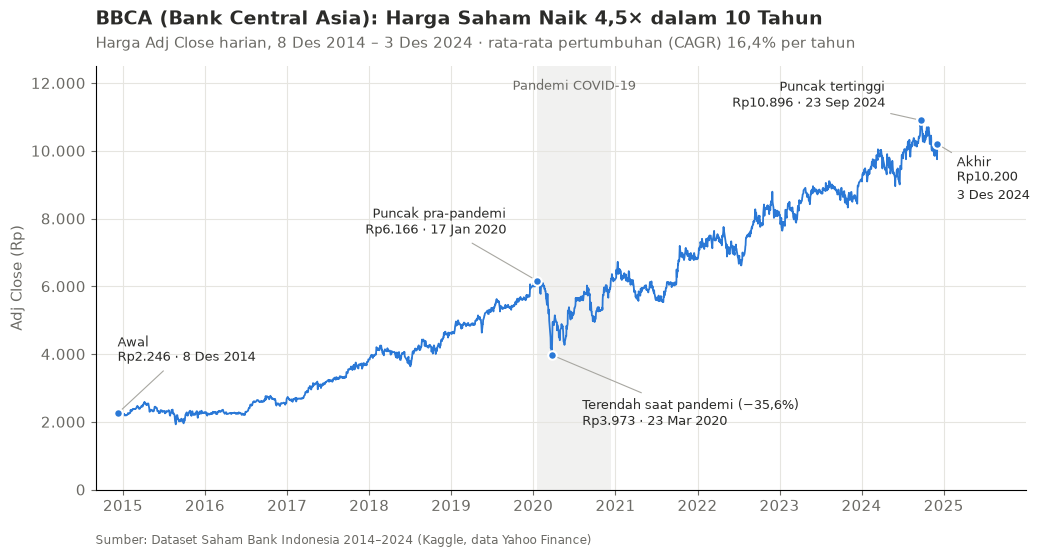

In [13]:
fig, ax = plt.subplots(figsize=(12, 5.5))

# pita periode pandemi: puncak pra-pandemi -> pulih
ax.axvspan(b_pra_tgl, b_pulih_tgl, color=B_PITA, alpha=0.13, lw=0, zorder=0)
ax.text(b_pra_tgl + (b_pulih_tgl - b_pra_tgl) / 2, 0.97, 'Pandemi COVID-19',
        transform=ax.get_xaxis_transform(), ha='center', va='top',
        fontsize=9, color=B_TINTA_2)

ax.plot(b_harga.index, b_harga, color=WARNA[b_ticker], lw=1.3, zorder=2)

b_turun = (b_dasar / b_pra_harga - 1) * 100
b_anotasi = [
    # (tanggal, harga, teks, offset (pt), ha, va)
    (b_awal_tgl, b_awal, f'Awal\n{b_rp(b_awal)} · {b_tgl(b_awal_tgl)}', (0, 34), 'left', 'bottom'),
    (b_pra_tgl, b_pra_harga, f'Puncak pra-pandemi\n{b_rp(b_pra_harga)} · {b_tgl(b_pra_tgl)}',
     (-22, 30), 'right', 'bottom'),
    (b_dasar_tgl, b_dasar, f'Terendah saat pandemi ({b_angka(b_turun)}%)\n{b_rp(b_dasar)} · {b_tgl(b_dasar_tgl)}',
     (22, -30), 'left', 'top'),
    (b_puncak_tgl, b_puncak, f'Puncak tertinggi\n{b_rp(b_puncak)} · {b_tgl(b_puncak_tgl)}',
     (-26, 6), 'right', 'bottom'),
    (b_akhir_tgl, b_akhir, f'Akhir\n{b_rp(b_akhir)}\n{b_tgl(b_akhir_tgl)}', (14, -6), 'left', 'top'),
]
for tgl, nilai, teks, offset, ha, va in b_anotasi:
    ax.scatter(tgl, nilai, s=38, color=WARNA[b_ticker], edgecolor='white', linewidth=1.5, zorder=4)
    ax.annotate(teks, xy=(tgl, nilai), xytext=offset, textcoords='offset points',
                ha=ha, va=va, fontsize=9, color=B_TINTA, linespacing=1.35,
                arrowprops=dict(arrowstyle='-', color='#a8a7a1', lw=0.8, shrinkA=2, shrinkB=4))

b_judul(ax, f'{b_ticker} ({NAMA_BANK[b_ticker]}): Harga Saham Naik {b_angka(b_kali)}× dalam 10 Tahun',
        f'Harga Adj Close harian, {b_tgl(b_awal_tgl)} – {b_tgl(b_akhir_tgl)} · '
        f'rata-rata pertumbuhan (CAGR) {b_angka(b_cagr * 100)}% per tahun')
ax.set_ylabel('Adj Close (Rp)', color=B_TINTA_2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax.set_ylim(0, 12500)
ax.set_xlim(pd.Timestamp('2014-09-01'), pd.Timestamp('2025-12-31'))
format_tanggal(ax)
ax.tick_params(colors=B_TINTA_2)
b_sumber(ax)

simpan_fig(fig, '01_line_bbca')
plt.show()

**Insight:** Harga BBCA naik dari Rp2.246 (8 Des 2014) menjadi Rp10.200 (3 Des 2024), yaitu 4,5× atau rata-rata 16,4% per tahun, dengan arah naik yang konsisten hampir sepanjang periode. Koreksi terbesar terjadi saat pandemi COVID-19: harga turun 35,6% dari Rp6.166 (17 Jan 2020) ke Rp3.973 (23 Mar 2020), lalu kembali melewati level pra-pandemi pada 14 Des 2020, sekitar 9 bulan (266 hari) setelah titik terendah. Puncak tertinggi Rp10.896 dicapai pada 23 Sep 2024, dan di akhir data harga berada 6,4% di bawah puncak tersebut.

## Area Plot

Area plot dipakai untuk menekankan **volume perdagangan** (jumlah lembar saham yang ditransaksikan). Volume harian keempat bank dijumlahkan per bulan lalu ditumpuk (*stacked area*), sehingga tinggi total area menunjukkan volume gabungan keempat bank dan tebal tiap lapisan menunjukkan kontribusi masing-masing bank.

Bulan yang datanya tidak penuh dibuang supaya total bulanan sebanding: Desember 2014 (data mulai 8 Des) dan Desember 2024 (hanya sampai 3 Des). Periode yang dipakai: Januari 2015 – November 2024 (119 bulan). Satuan volume adalah miliar lembar (volume Yahoo Finance sudah disesuaikan dengan stock split).

In [14]:
b_vol_bulan = (vol_wide.resample('ME').sum() / 1e9).loc['2015-01':'2024-11']
b_total_bulan = b_vol_bulan.sum(axis=1)

b_vol_tahun = b_vol_bulan.groupby(b_vol_bulan.index.year).sum()
b_vol_tahun['Total'] = b_vol_tahun.sum(axis=1)
b_porsi = b_vol_bulan.sum() / b_vol_bulan.sum().sum() * 100

print(f'Rata-rata volume gabungan : {b_total_bulan.mean():.2f} miliar lembar/bulan')
b_bbri_teratas = (b_vol_bulan.idxmax(axis=1) == 'BBRI').sum()
print(f'Bulan tertinggi           : {b_bln(b_total_bulan.idxmax())} ({b_total_bulan.max():.2f} miliar lembar, '
      f'{b_total_bulan.max() / b_total_bulan.mean():.1f}x rata-rata)')
print('Porsi volume tiap bank (%):', b_porsi.round(1).to_dict())
print(f'BBRI volume terbesar di   : {b_bbri_teratas} dari {len(b_vol_bulan)} bulan')
print('\nVolume per tahun (miliar lembar; 2024 = Jan-Nov):')
b_vol_tahun.round(1)

Rata-rata volume gabungan : 7.97 miliar lembar/bulan
Bulan tertinggi           : Jun 2020 (16.81 miliar lembar, 2.1x rata-rata)
Porsi volume tiap bank (%): {'BBCA': 21.1, 'BBRI': 39.6, 'BMRI': 24.2, 'BBNI': 15.1}
BBRI volume terbesar di   : 115 dari 119 bulan

Volume per tahun (miliar lembar; 2024 = Jan-Nov):


Ticker,BBCA,BBRI,BMRI,BBNI,Total
Date,,,,,
2015,17.5,38.5,23.2,14.1,93.2
2016,23.1,33.7,22.8,13.5,93.0
2017,20.1,25.4,17.9,10.1,73.6
2018,18.5,32.1,17.9,10.6,79.1
2019,15.7,28.2,21.3,10.4,75.5
2020,25.6,53.1,30.7,27.2,136.6
2021,20.2,40.3,22.5,15.4,98.4
2022,23.4,40.8,28.6,16.1,108.9
2023,18.2,31.0,21.3,13.6,84.1


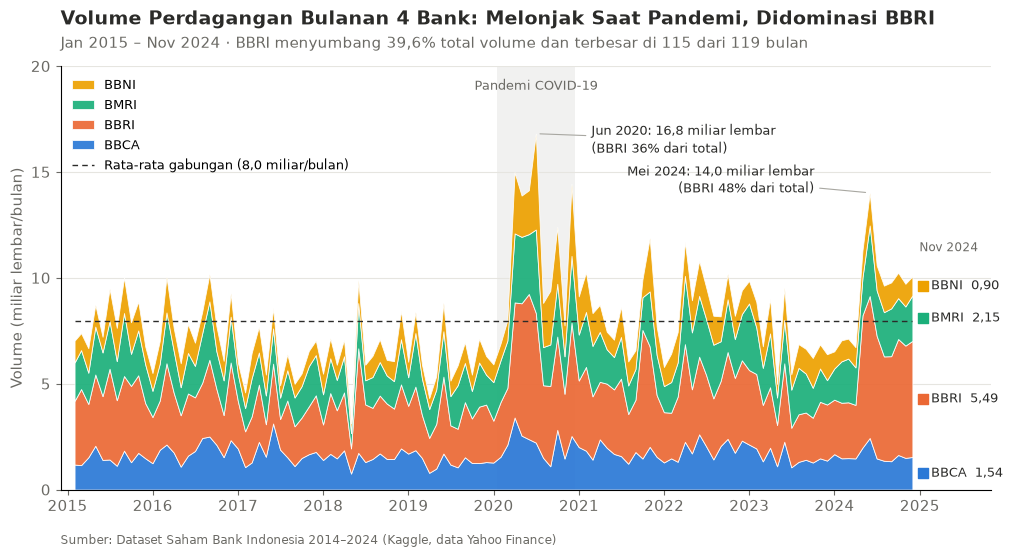

In [15]:
fig, ax = plt.subplots(figsize=(12, 5.5))

ax.axvspan(b_pra_tgl, b_pulih_tgl, color=B_PITA, alpha=0.13, lw=0, zorder=0)
ax.text(b_pra_tgl + (b_pulih_tgl - b_pra_tgl) / 2, 0.97, 'Pandemi COVID-19',
        transform=ax.get_xaxis_transform(), ha='center', va='top',
        fontsize=9, color=B_TINTA_2)

# urutan tumpukan bawah -> atas mengikuti TICKERS; garis putih tipis = jeda antar lapisan
ax.stackplot(b_vol_bulan.index, [b_vol_bulan[t] for t in TICKERS],
             colors=[WARNA[t] for t in TICKERS], labels=TICKERS,
             edgecolor='white', linewidth=0.6, alpha=0.92, zorder=2)

# label langsung di ujung kanan, di tengah tiap lapisan bulan terakhir
b_x_akhir = b_vol_bulan.index[-1]
b_atas = b_vol_bulan.iloc[-1].cumsum()
b_tengah = (b_atas - b_vol_bulan.iloc[-1] / 2).tolist()
for i in range(1, len(b_tengah)):           # jaga jarak minimal antar label
    b_tengah[i] = max(b_tengah[i], b_tengah[i - 1] + 1.3)
for t, y in zip(TICKERS, b_tengah):
    ax.scatter(b_x_akhir + pd.Timedelta(days=45), y, marker='s', s=42, color=WARNA[t], zorder=3)
    ax.text(b_x_akhir + pd.Timedelta(days=80), y,
            f'{t}  {b_angka(b_vol_bulan[t].iloc[-1], 2)}', va='center', fontsize=9.5, color=B_TINTA)
ax.text(b_x_akhir + pd.Timedelta(days=30), b_tengah[-1] + 1.5, b_bln(b_x_akhir),
        fontsize=8.5, color=B_TINTA_2, va='bottom')

# anotasi dua puncak volume gabungan
b_puncak_vol = [
    (b_total_bulan.idxmax(), (40, -4), 'left'),
    (b_total_bulan.loc['2021':].idxmax(), (-40, 10), 'right'),
]
for tgl, offset, ha in b_puncak_vol:
    total = b_total_bulan[tgl]
    porsi_bbri = b_vol_bulan.loc[tgl, 'BBRI'] / total * 100
    ax.annotate(f'{b_bln(tgl)}: {b_angka(total)} miliar lembar\n(BBRI {b_angka(porsi_bbri, 0)}% dari total)',
                xy=(tgl, total), xytext=offset, textcoords='offset points', ha=ha, va='center',
                fontsize=9, color=B_TINTA, linespacing=1.35,
                arrowprops=dict(arrowstyle='-', color='#a8a7a1', lw=0.8, shrinkA=2, shrinkB=3))

# garis rata-rata hanya sepanjang data, supaya tidak memotong label di kanan
ax.plot([b_vol_bulan.index[0], b_x_akhir], [b_total_bulan.mean()] * 2, color=B_TINTA,
        lw=1.0, ls=(0, (4, 3)), zorder=3,
        label=f'Rata-rata gabungan ({b_angka(b_total_bulan.mean())} miliar/bulan)')

b_judul(ax, 'Volume Perdagangan Bulanan 4 Bank: Melonjak Saat Pandemi, Didominasi BBRI',
        'Jan 2015 – Nov 2024 · '
        f'BBRI menyumbang {b_angka(b_porsi["BBRI"])}% total volume dan terbesar di '
        f'{b_bbri_teratas} dari {len(b_vol_bulan)} bulan')
ax.set_ylabel('Volume (miliar lembar/bulan)', color=B_TINTA_2)
ax.set_ylim(0, 20)
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.set_xlim(b_vol_bulan.index[0] - pd.Timedelta(days=60), pd.Timestamp('2025-10-31'))
ax.grid(axis='x', visible=False)
format_tanggal(ax)
ax.tick_params(colors=B_TINTA_2)

# legend: lapisan urut sesuai tumpukan visual (atas -> bawah), lalu garis rata-rata
h, l = ax.get_legend_handles_labels()
ax.legend(h[:4][::-1] + h[4:], l[:4][::-1] + l[4:], loc='upper left', ncol=1, fontsize=9.5,
          handlelength=1.6, labelspacing=0.45, bbox_to_anchor=(0, 1.0))
b_sumber(ax)

simpan_fig(fig, '02_area_volume')
plt.show()

**Insight:** Volume gabungan keempat bank rata-rata 8,0 miliar lembar per bulan, dan BBRI menjadi penyumbang terbesar (39,6% dari total volume, terbesar di 115 dari 119 bulan). Lonjakan paling tajam terjadi saat pandemi: total volume 2020 mencapai 136,6 miliar lembar (naik 80,9% dari 2019) dengan puncak 16,8 miliar lembar pada Juni 2020 (2,1× rata-rata), dan volume BBNI pada 2020 naik 2,6× dibanding 2019. Lonjakan kedua pada Mei 2024 (14,0 miliar lembar) polanya berbeda karena hampir separuhnya (48%) berasal dari BBRI, sejalan dengan porsi BBRI sepanjang Jan–Nov 2024 yang naik menjadi 49,6%.

## Multiple Time Series

Untuk membandingkan pertumbuhan harga keempat bank, harga Adj Close diubah menjadi **indeks dengan minggu pertama = 100**, sehingga semua bank mulai dari titik yang sama meskipun harga nominalnya berbeda. Data harian diubah menjadi mingguan (harga penutupan terakhir tiap minggu) agar garis lebih bersih dan tren jangka panjang lebih mudah dibandingkan. Nama bank ditulis langsung di ujung garis (*direct labeling*) sebagai pengganti legend.


In [16]:
# harga penutupan terakhir tiap minggu; minggu tanpa hari bursa (libur Lebaran) dibuang
c_mingguan = adj_wide.resample('W-FRI').last().dropna()

# indeks harga: minggu pertama = 100
c_indeks = c_mingguan / c_mingguan.iloc[0] * 100
c_akhir = c_indeks.iloc[-1].sort_values(ascending=False)
c_akhir.round(1).to_frame('Indeks akhir')


,Indeks akhir
Ticker,
BBCA,454.9
BMRI,349.8
BBRI,287.6
BBNI,209.0


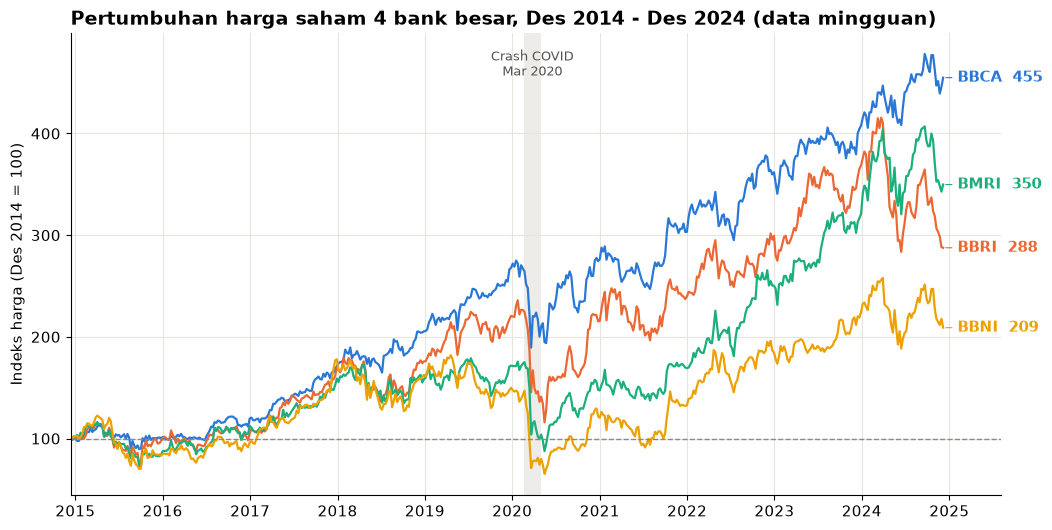

In [17]:
fig, ax = plt.subplots(figsize=(12, 6))
for t in TICKERS:
    ax.plot(c_indeks.index, c_indeks[t], color=WARNA[t], lw=1.6)
ax.axhline(100, color='#8a8984', lw=1, ls='--')

# direct label di ujung kanan garis; label digeser ke bawah bila terlalu dekat dengan label di atasnya
c_jarak = (c_indeks.max().max() - c_indeks.min().min()) * 0.05
c_x_akhir = c_indeks.index[-1]
c_y_label = []
for t, v in c_akhir.items():
    y = v if not c_y_label or c_y_label[-1] - v >= c_jarak else c_y_label[-1] - c_jarak
    c_y_label.append(y)
    ax.annotate(f'{t}  {v:.0f}', xy=(c_x_akhir, v), xytext=(c_x_akhir + pd.Timedelta(days=60), y),
                color=WARNA[t], fontsize=11, fontweight='bold', va='center',
                arrowprops=dict(arrowstyle='-', color=WARNA[t], lw=0.8))

# penanda crash COVID-19
ax.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-04-30'), color='#e6e5e0', alpha=0.7, lw=0)
ax.text(pd.Timestamp('2020-03-25'), ax.get_ylim()[1] * 0.97, 'Crash COVID\nMar 2020',
        ha='center', va='top', fontsize=9, color='#52514e')

format_tanggal(ax)
ax.set_xlim(c_indeks.index[0], c_x_akhir + pd.Timedelta(days=240))
ax.set_ylabel('Indeks harga (Des 2014 = 100)')
ax.set_title('Pertumbuhan harga saham 4 bank besar, Des 2014 - Des 2024 (data mingguan)')
simpan_fig(fig, '03_multiple_time_series')
plt.show()


**Insight:** Dalam 10 tahun, BBCA tumbuh paling tinggi (indeks ±455, naik sekitar 4,5×), disusul BMRI (±350), BBRI (±288), dan BBNI (±209). Keempat bank bergerak hampir seragam pada 2015–2017, lalu mulai terpisah sejak 2018. Saat crash COVID Maret 2020 semua bank anjlok bersamaan, bahkan BBNI sempat turun di bawah harga awal 2014 (indeks 71) dan BMRI kembali ke level harga awal (indeks 99,7). BBCA paling cepat pulih ke level sebelum pandemi (Des 2020), dibanding BBRI (Jan 2021) serta BMRI dan BBNI (Jan–Feb 2022).


## Seasonal Plot / Calendar Heatmap

Untuk melihat pola musiman, dihitung **return bulanan** tiap bank, yaitu perubahan harga dari akhir bulan sebelumnya ke akhir bulan tersebut. Return dari 2015–2024 lalu dirata-ratakan per bulan kalender (Jan–Des), sehingga tiap kotak menunjukkan rata-rata return bank tersebut pada bulan itu selama 2015–2024. Biru berarti rata-rata naik, merah berarti rata-rata turun. Desember 2014 tidak dipakai karena tidak punya bulan pembanding, dan Desember 2024 tidak dipakai karena hanya berisi 2 hari bursa. Dengan demikian Januari–November dirata-ratakan dari 10 nilai, sedangkan Desember dari 9 nilai (2015–2023).


In [18]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# return bulanan (%): harga akhir bulan dibanding akhir bulan sebelumnya
c_return = adj_wide.resample('ME').last().pct_change() * 100
# Des 2014 tidak punya bulan pembanding, Des 2024 hanya berisi 2 hari bursa
c_return = c_return.loc['2015-01':'2024-11']

# baris = bank, kolom = bulan kalender
c_bulan = c_return.index.month
c_rata = c_return.groupby(c_bulan).mean().T
c_rata.round(1)


Date,1,2,3,4,5,6,7,8,9,10,11,12
Ticker,,,,,,,,,,,,
BBCA,1.3,1.8,-0.1,0.2,-0.5,0.8,3.3,3.2,-0.3,2.3,0.7,4.2
BBRI,0.1,4.5,0.4,-4.3,1.2,-1.6,2.0,3.4,-2.9,4.2,2.7,5.0
BMRI,2.2,1.3,2.0,-2.0,-2.2,1.1,3.7,3.0,-2.9,5.6,0.3,3.9
BBNI,-0.2,3.8,-1.1,-2.0,-2.3,-2.3,1.0,5.2,-2.7,5.4,4.8,4.3


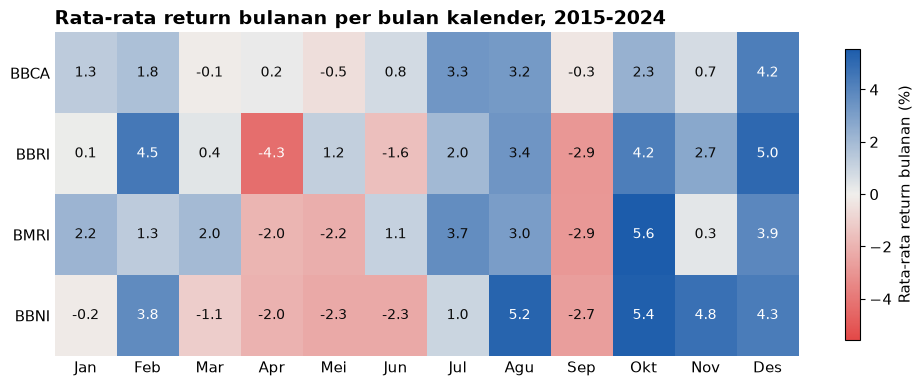

In [19]:
BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
# merah = turun, abu-abu terang = 0, biru = naik
c_cmap = LinearSegmentedColormap.from_list('c_merah_biru', ['#e34948', '#f0efec', '#1c5cab'])
c_batas = np.abs(c_rata.values).max()
c_norm = TwoSlopeNorm(vcenter=0, vmin=-c_batas, vmax=c_batas)

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(c_rata.values, cmap=c_cmap, norm=c_norm, aspect='auto')
ax.set_xticks(range(12), BULAN)
ax.set_yticks(range(len(TICKERS)), c_rata.index)
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)

# tulis nilai rata-rata return di tiap kotak
for i in range(c_rata.shape[0]):
    for j in range(c_rata.shape[1]):
        v = c_rata.iat[i, j]
        warna_teks = 'white' if abs(c_norm(v) - 0.5) > 0.33 else '#0b0b0b'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=10, color=warna_teks)

fig.colorbar(im, ax=ax, shrink=0.9, label='Rata-rata return bulanan (%)')
ax.set_title('Rata-rata return bulanan per bulan kalender, 2015-2024')
simpan_fig(fig, '04_seasonal_heatmap')
plt.show()


**Insight:** Desember menjadi bulan dengan rata-rata return tertinggi bagi keempat bank (+3,9% hingga +5,0%), dan Oktober juga kuat, terutama untuk BMRI (+5,6%), BBNI (+5,4%), dan BBRI (+4,2%). Sebaliknya, September negatif di semua bank (−0,3% hingga −2,9%), dan April–Juni rata-rata negatif pada BBRI, BMRI, dan BBNI, sedangkan BBCA bergerak di sekitar nol pada bulan-bulan tersebut (−0,5% hingga +0,8%). BBCA memiliki warna paling pucat, artinya pergerakan bulanannya paling stabil dibanding tiga bank lain. Karena setiap kotak hanya rata-rata dari 9–10 nilai, pola ini bersifat kecenderungan dan belum tentu berulang pada tahun-tahun berikutnya.

## Moving Average

Moving average menghitung rata-rata harga pada jendela (window) waktu tertentu untuk memperhalus fluktuasi harian dan memperjelas arah tren jangka panjang. Tiga ukuran window digunakan:
- MA-20 (20-day average): mencakup 20 hari bursa (sekitar 1 bulan kalender), paling responsif terhadap pembalikan arah harga namun masih sensitif terhadap fluktuasi jangka pendek.
- MA-50 (50-day average): mencakup 50 hari bursa (sekitar 2,5 bulan kalender), menyeimbangkan kehalusan kurva dan kecepatan reaksi terhadap perubahan tren.
- MA-100 (100-day average): mencakup 100 hari bursa (sekitar 5 bulan kalender), menghasilkan kurva yang sangat halus untuk memetakan tren jangka menengah-panjang.

Trade-off NaN: Perhitungan window sebesar *n* membutuhkan minimal *n* data historis. Akibatnya, sebanyak *n* - 1 baris pertama pada deret waktu bernilai NaN (tidak terdefinisi). MA-20 kehilangan 19 hari pertama, MA-50 kehilangan 49 hari pertama, dan MA-100 kehilangan 99 hari pertama. Semakin besar ukuran window, semakin bersih kurva dari noise, namun semakin banyak data awal yang terpotong serta semakin lambat kurva bereaksi (lagging) terhadap momentum pergerakan harga terkini.

Trade-off NaN pada deret waktu:
  MA-20  (20-day)  : 19 baris awal bernilai NaN
  MA-50  (50-day)  : 49 baris awal bernilai NaN
  MA-100 (100-day) : 99 baris awal bernilai NaN


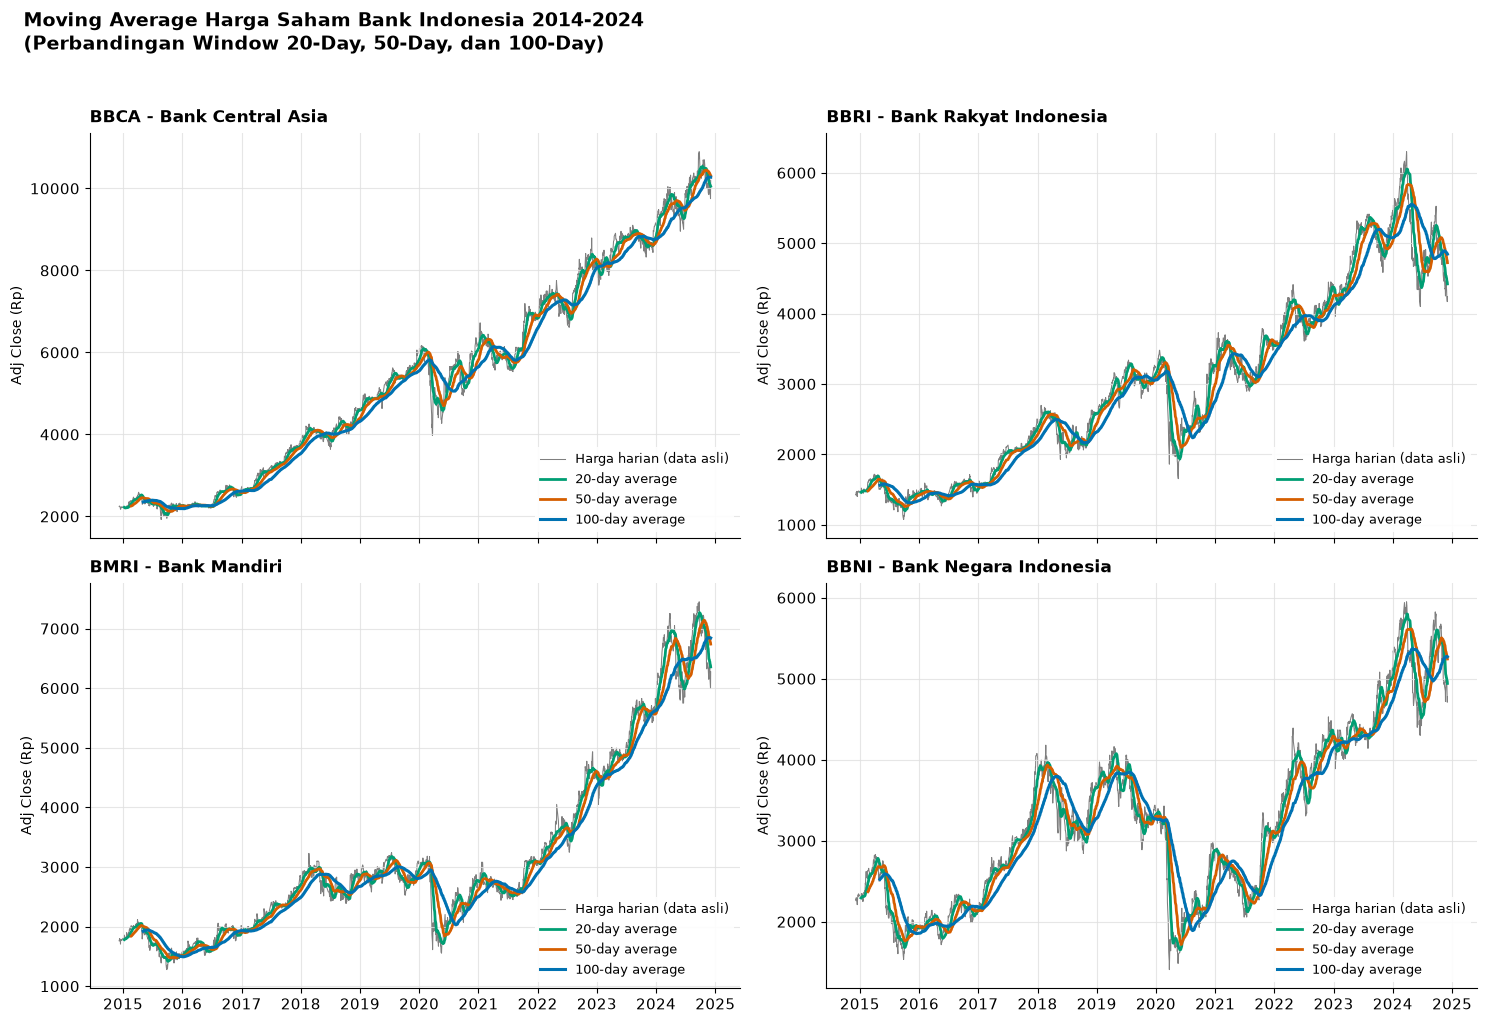

In [20]:
# Parameter window
D_WINDOW_PENDEK = 20
D_WINDOW_MENENGAH = 50
D_WINDOW_PANJANG = 100

# Hitung Moving Average untuk semua bank
d_ma20 = adj_wide.rolling(D_WINDOW_PENDEK).mean()
d_ma50 = adj_wide.rolling(D_WINDOW_MENENGAH).mean()
d_ma100 = adj_wide.rolling(D_WINDOW_PANJANG).mean()

# Informasi trade-off NaN per window
print('Trade-off NaN pada deret waktu:')
print(f'  MA-{D_WINDOW_PENDEK}  (20-day)  : {D_WINDOW_PENDEK - 1} baris awal bernilai NaN')
print(f'  MA-{D_WINDOW_MENENGAH}  (50-day)  : {D_WINDOW_MENENGAH - 1} baris awal bernilai NaN')
print(f'  MA-{D_WINDOW_PANJANG} (100-day) : {D_WINDOW_PANJANG - 1} baris awal bernilai NaN')

D_C_RAW = '#000000'   # hitam tipis untuk data harian asli
D_C_MA20 = '#009E73'   # hijau teal
D_C_MA50 = '#D55E00'   # oranye vermilion
D_C_MA100 = '#0072B2'  # biru kuat

# Visualisasi
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
axes = axes.flatten()
for idx, ticker in enumerate(TICKERS):
    ax = axes[idx]
    ax.plot(adj_wide.index, adj_wide[ticker],
            color=D_C_RAW, alpha=0.50, linewidth=0.75,
            label='Harga harian (data asli)', zorder=1)
    ax.plot(d_ma20.index, d_ma20[ticker],
            color=D_C_MA20, linewidth=2.0,
            label=f'{D_WINDOW_PENDEK}-day average', zorder=3)
    ax.plot(d_ma50.index, d_ma50[ticker],
            color=D_C_MA50, linewidth=2.0,
            label=f'{D_WINDOW_MENENGAH}-day average', zorder=4)
    ax.plot(d_ma100.index, d_ma100[ticker],
            color=D_C_MA100, linewidth=2.2,
            label=f'{D_WINDOW_PANJANG}-day average', zorder=5)
    ax.set_title(f'{ticker} - {NAMA_BANK[ticker]}', fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('Adj Close (Rp)', fontsize=10)
    format_tanggal(ax)
    ax.grid(True, linestyle='-', color='#e0e0e0', linewidth=0.8, alpha=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(loc='lower right', fontsize=9, frameon=True,
              facecolor='white', framealpha=0.9, edgecolor='none')
fig.suptitle(
    'Moving Average Harga Saham Bank Indonesia 2014-2024\n'
    '(Perbandingan Window 20-Day, 50-Day, dan 100-Day)',
    fontsize=14, fontweight='bold', x=0.02, ha='left', y=1.02
)
fig.tight_layout()
simpan_fig(fig, '05a_moving_average')
plt.show()

**Insight:** MA-20 (hijau) bereaksi paling cepat terhadap fluktuasi harga harian dan penurunan mendadak saat awal pandemi COVID-19 (Maret 2020), sedangkan MA-100 (biru) memperlihatkan arah tren sekuler jangka panjang yang jauh lebih stabil dan tahan terhadap noise. Saham BBCA dan BMRI menunjukkan tren naik paling konsisten sepanjang 2014-2024 dengan kurva MA-100 yang menanjak pada 79% (BBCA) dan 73% (BMRI) hari pengamatan, dibanding 66% (BBRI) dan 63% (BBNI). BBRI mengalami koreksi tren yang cukup dalam pada 2024 (dari puncak Rp6.300 pada Maret 2024 ke Rp4.240 di akhir data), sedangkan BBNI cenderung turun pada rentang 2018-2021 (sekitar -24%) dengan rentang harga hampir 3×.

### Detail Trade-off Window pada BBCA

Grafik berikut memperbesar saham BBCA (Bank Central Asia) untuk mengilustrasikan trade-off antara responsivitas kurva, kehalusan data, serta area data awal yang hilang (NaN) pada MA-100.

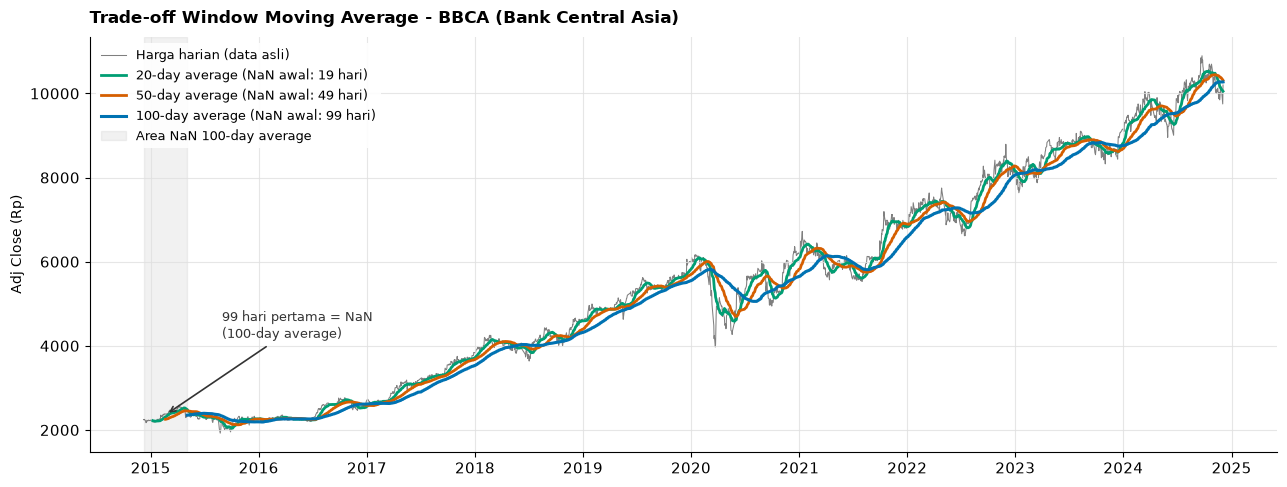

In [21]:
# Ilustrasi detail trade-off window dan area NaN pada BBCA
d_ticker_detail = 'BBCA'
d_seri = adj_wide[d_ticker_detail]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(d_seri.index, d_seri,
        color='#000000', alpha=0.50, linewidth=0.75,
        label='Harga harian (data asli)', zorder=1)
ax.plot(d_ma20.index, d_ma20[d_ticker_detail],
        color='#009E73', linewidth=2.0,
        label=f'20-day average (NaN awal: {D_WINDOW_PENDEK-1} hari)', zorder=3)
ax.plot(d_ma50.index, d_ma50[d_ticker_detail],
        color='#D55E00', linewidth=2.0,
        label=f'50-day average (NaN awal: {D_WINDOW_MENENGAH-1} hari)', zorder=4)
ax.plot(d_ma100.index, d_ma100[d_ticker_detail],
        color='#0072B2', linewidth=2.2,
        label=f'100-day average (NaN awal: {D_WINDOW_PANJANG-1} hari)', zorder=5)
d_nan_akhir = d_seri.index[D_WINDOW_PANJANG - 1]
ax.axvspan(d_seri.index[0], d_nan_akhir,
           color='#BBBBBB', alpha=0.20,
           label='Area NaN 100-day average', zorder=0)
ax.annotate(
    f'{D_WINDOW_PANJANG-1} hari pertama = NaN\n(100-day average)',
    xy=(d_seri.index[D_WINDOW_PANJANG // 2], d_seri.iloc[D_WINDOW_PANJANG // 2]),
    xytext=(40, 55), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#333333', lw=1.2),
    fontsize=9.5, color='#333333'
)
ax.set_title(f'Trade-off Window Moving Average - {d_ticker_detail} ({NAMA_BANK[d_ticker_detail]})',
             fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel('Adj Close (Rp)', fontsize=10)
format_tanggal(ax)
ax.grid(True, linestyle='-', color='#e0e0e0', linewidth=0.8, alpha=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper left', fontsize=9, frameon=True,
          facecolor='white', framealpha=0.9, edgecolor='none')
fig.tight_layout()
simpan_fig(fig, '05b_ma_tradeoff_bbca')
plt.show()

**Insight:** Pada BBCA, MA-20 sangat cepat menangkap titik balik harga pada Maret 2020 ketika harga anjlok akibat pandemi lalu pulih kembali. Namun, kurva MA-20 masih bergelombang mengikuti volatilitas jangka pendek. Sebaliknya, MA-100 memberikan garis tren sekuler yang sangat mulus dan menggambarkan apresiasi modal jangka panjang BBCA, dengan konsekuensi kehilangan data 99 hari bursa pertama (sekitar 5 bulan) serta adanya jeda waktu dalam mendeteksi perubahan tren mendadak.

## Fitting Model

`numpy.polyfit` digunakan untuk memodelkan tren harga saham secara matematis melalui regresi polinomial
- Data Aktual Bulanan: Data harian diagregasi menjadi rata-rata bulanan agar sebaran titik tampak bersih, proporsional, dan terbebas dari penumpukan titik harian yang terlalu padat.
- Fit Linear (derajat 1): Memodelkan laju kenaikan harga konstan sebagai garis lurus sepanjang 10 tahun.
- Fit Kuadratik (derajat 2): Menangkap dinamika percepatan atau perlambatan tren harga saham (kurva polinomial lengkung).

Visualisasi dirancang dengan skema colorblind-friendly, menggunakan titik biru bersambung garis untuk data aktual, garis putus-putus hitam untuk fit kuadratik, serta garis putus-titik orange untuk fit linear.

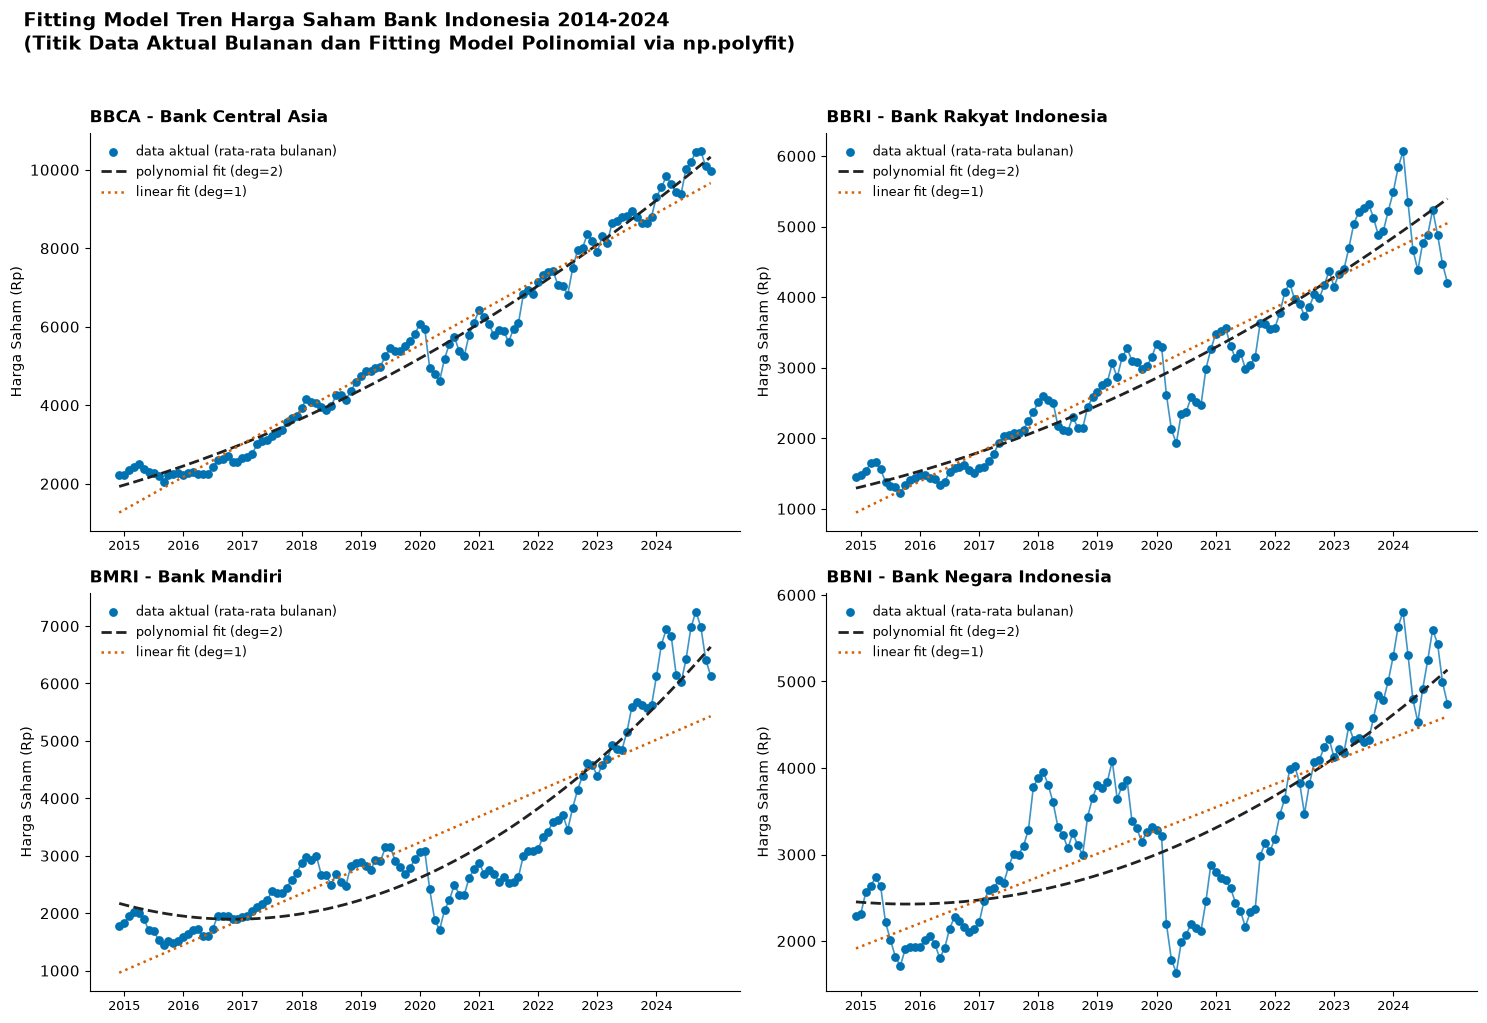

In [22]:
# Resample harga saham ke rata-rata bulanan untuk visualisasi titik bersih
d_bulanan = adj_wide.resample('ME').mean()

# Konversi waktu ke ordinal numerik (bulan ke-n sejak awal observasi)
d_bulan_num = np.arange(len(d_bulanan))
d_x_halus = np.linspace(d_bulan_num[0], d_bulan_num[-1], 300)

# Fitting polinomial linear (deg=1) dan kuadratik (deg=2) per bank
d_koef_lin = {}
d_koef_kua = {}
for ticker in TICKERS:
    y = d_bulanan[ticker].values
    d_koef_lin[ticker] = np.polyfit(d_bulan_num, y, 1)
    d_koef_kua[ticker] = np.polyfit(d_bulan_num, y, 2)

D_C_ACTUAL = '#0072B2'   # biru Okabe-Ito untuk titik dan garis data aktual
D_C_QUAD   = '#222222'   # hitam arang untuk kurva fit kuadratik
D_C_LIN    = '#D55E00'   # oranye vermilion untuk garis fit linear

# Visualisasi
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=False)
axes = axes.flatten()

for idx, ticker in enumerate(TICKERS):
    ax = axes[idx]
    y = d_bulanan[ticker].values
    ax.plot(d_bulan_num, y, color=D_C_ACTUAL, linewidth=1.2, alpha=0.75, zorder=2)
    ax.scatter(d_bulan_num, y, color=D_C_ACTUAL, s=28, zorder=3,
               label='data aktual (rata-rata bulanan)')
    d_tren_kua = np.polyval(d_koef_kua[ticker], d_x_halus)
    ax.plot(d_x_halus, d_tren_kua, color=D_C_QUAD, linewidth=2.0, linestyle='--',
            label='polynomial fit (deg=2)', zorder=4)
    d_tren_lin = np.polyval(d_koef_lin[ticker], d_x_halus)
    ax.plot(d_x_halus, d_tren_lin, color=D_C_LIN, linewidth=1.8, linestyle=':',
            label='linear fit (deg=1)', zorder=4)
    tik_posisi = [i for i, d in enumerate(d_bulanan.index) if d.month == 1]
    tik_label = [d_bulanan.index[i].year for i in tik_posisi]
    ax.set_xticks(tik_posisi)
    ax.set_xticklabels(tik_label, fontsize=9)

    ax.set_title(f'{ticker} - {NAMA_BANK[ticker]}', fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('Harga Saham (Rp)', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.legend(loc='upper left', fontsize=9, frameon=False)
fig.suptitle(
    'Fitting Model Tren Harga Saham Bank Indonesia 2014-2024\n'
    '(Titik Data Aktual Bulanan dan Fitting Model Polinomial via np.polyfit)',
    fontsize=14, fontweight='bold', x=0.02, ha='left', y=1.02
)
fig.tight_layout()
simpan_fig(fig, '06_fitting_model')
plt.show()

**Insight:** Fit kuadratik menangkap kelengkungan tren lebih baik daripada fit linear, terutama pada BMRI (R² naik dari 0,75 menjadi 0,88). Pada BBCA selisihnya kecil (0,97 menjadi 0,98) karena trennya sudah hampir lurus. BBCA dan BMRI menunjukkan percepatan kenaikan harga setelah 2020 dengan kurva yang melengkung ke atas. BBRI tumbuh kuat hingga 2023 sebelum melandai di 2024, sedangkan BBNI paling sulit dijelaskan oleh kedua model (R² linear 0,57 dan kuadratik 0,62) karena harganya naik-turun dalam rentang yang panjang.

In [23]:
# Ringkasan koefisien regresi model polinomial
def d_r2(ticker, koef):
    y = d_bulanan[ticker].values
    return 1 - ((y - np.polyval(koef, d_bulan_num)) ** 2).sum() / ((y - y.mean()) ** 2).sum()

d_ringkasan = pd.DataFrame({
    'Kemiringan Linear (Rp/bulan)': {t: round(d_koef_lin[t][0], 1) for t in TICKERS},
    'Intersep Linear (Rp)':         {t: round(d_koef_lin[t][1], 0) for t in TICKERS},
    'Koef. Kuadratik a (x^2)':      {t: f"{d_koef_kua[t][0]:.4f}" for t in TICKERS},
    'Koef. Kuadratik b (x)':        {t: f"{d_koef_kua[t][1]:.2f}" for t in TICKERS},
    'R² Linear':                    {t: round(d_r2(t, d_koef_lin[t]), 2) for t in TICKERS},
    'R² Kuadratik':                 {t: round(d_r2(t, d_koef_kua[t]), 2) for t in TICKERS},
})
d_ringkasan.index.name = 'Ticker'
print('Ringkasan Koefisien Model Tren:')
d_ringkasan

Ringkasan Koefisien Model Tren:


,Kemiringan Linear (Rp/bulan),Intersep Linear (Rp),Koef. Kuadratik a (x^2),Koef. Kuadratik b (x),R² Linear,R² Kuadratik
Ticker,,,,,,
BBCA,70.0,1266.0,0.2792,36.48,0.97,0.98
BBRI,34.2,947.0,0.1453,16.74,0.89,0.91
BMRI,37.2,963.0,0.5073,-23.64,0.75,0.88
BBNI,22.3,1915.0,0.2260,-4.78,0.57,0.62


**Insight:** Saham BBCA membukukan kemiringan linear tertinggi (+70,0 Rp/bulan), disusul BMRI (+37,2), BBRI (+34,2), dan BBNI (+22,3). Koefisien kuadratik bernilai positif pada keempat saham, artinya kenaikan harga cenderung semakin cepat sepanjang 2014-2024, dan efek ini paling kuat pada BMRI (0,5073).

## Deklarasi Penggunaan AI

"Saya, [Nama Lengkap] / [NIM], menyatakan bahwa saya [menggunakan / tidak menggunakan] alat AI generatif dalam pengerjaan tugas ini. Seluruh interpretasi, insight, dan kesimpulan yang disampaikan merupakan hasil pemahaman saya sendiri."

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Tingkat Ketergantungan |
|---|---|---|---|---|
| 1 | | | | |

Screenshot prompt dikumpulkan terpisah dalam berkas `Screenshot_AI_[NIM]`.